# Brownian motion
The elementary analysis of returns in the notebook random_behavior_of_assets teaches us that we need to understand the Brownian motion. In this notebook we will start with the Brownian Motion (BM) and go all up to the discretization of the Geometric Brownian Motion. The required functions for the simulations are in the source directory.

In [1]:
import sys
sys.path.append("../src")

In [2]:
import numpy as np
import matplotlib.pyplot as plt

In [3]:
from geometric_brownian_motion import brownian_motion, geometric_brownian_motion, discretized_geometric_brownian_motion

## Brownian motion without drift

 We start with the basic brownian motion
$$ dW= dt Z $$ with $Z\sim  \mathcal N (0,1)$ 

In [4]:
m_paths=10
seed=120910923091823
n_steps=252
T=1
times = [i * 1 / n_steps for i in range(n_steps+1)]

In [5]:
W=brownian_motion(T=T, n_steps=n_steps, m_paths=m_paths, seed=seed)

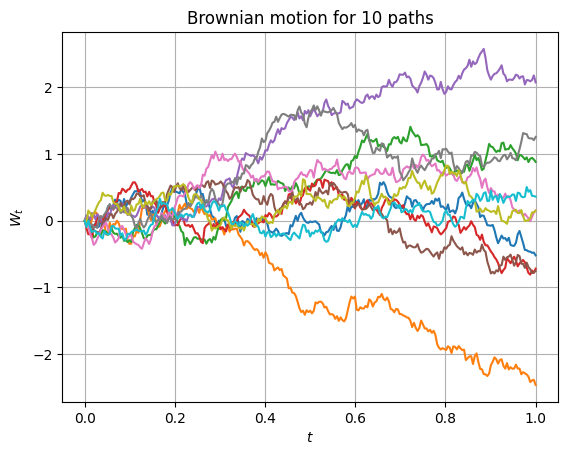

In [6]:
for path in W:
    plt.plot(times, path)
plt.title("Brownian motion")
plt.grid(True)
plt.xlabel('$t$')
plt.ylabel('$W_t$')
plt.title("Brownian motion for "+str(m_paths)+" paths")
plt.show()

## Geometric Brownian Motion: exact solution

The geometric Brownian Motion is governed by the stochastic differential equation
$$
dS_t= \mu S_t dt+ \sigma S_t dW_t
$$

There is a closed form solution in this case

$$
S_T=S_0 \exp((\mu-\frac 12 \sigma^2)T + \sigma W_T)
$$

We simulate the discretized version of the solution

In [7]:
drift=0.3
volatility=0.5
S0=100

In [8]:
t, S =geometric_brownian_motion(T=T, drift=drift, volatility=volatility, n_steps=n_steps, m_paths=m_paths, seed=seed)

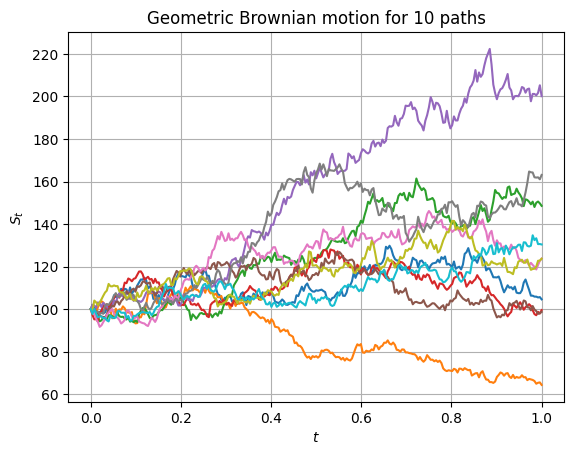

In [9]:
for path in S:
    plt.plot(t, path)
plt.grid(True)
plt.xlabel('$t$')
plt.ylabel('$S_t$')
plt.title("Geometric Brownian motion for "+str(m_paths)+" paths")
plt.show()

## Discretized solution
In general we do not have access to a exact solution, so we need to approximate it. The discretization using Euler-Maruyama gives 

$$S_{t_{n+1}}= S_{t_{n}} (1+\mu \Delta t + \sigma \Delta W_n)\ ,$$

which difers from the exact solution by terms or order $\mathcal O (\Delta t)$ 

In [10]:
t, S_discrete = discretized_geometric_brownian_motion(T=T, drift=drift, volatility=volatility, n_steps=n_steps, m_paths=m_paths, seed=seed)

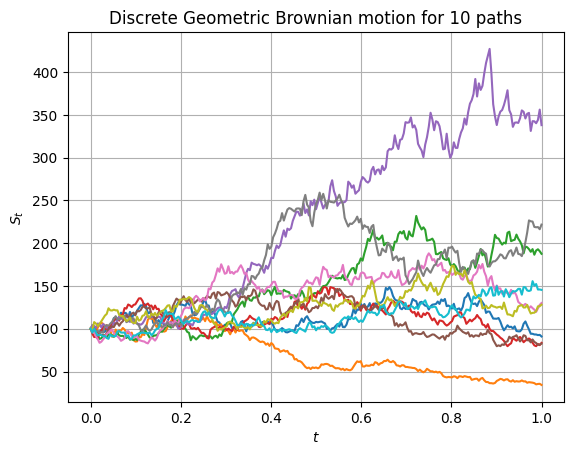

In [11]:
for path in S_discrete:
    plt.plot(t, path)
plt.grid(True)
plt.xlabel('$t$')
plt.ylabel('$S_t$')
plt.title("Discrete Geometric Brownian motion for "+str(m_paths)+" paths")
plt.show()

### More interesting is to look at the errors

- We compare the Euler approximation as the number of steps varies against the exact solution evaluated at T
- The errors should be of order $\mathcal O (\Delta t)$ 

In [12]:
#this is the exact solution at time T
def exact_sol_gbm(S0, drift, volatility, T, W_T):
    return S0*np.exp((drift-0.5*volatility**2)*T+volatility*W_T)

#Euler approximation 
def euler_approximation(S0, drift, volatility, T, n_steps, dW):
    dt=T/n_steps
    factors=1+drift*dt+volatility*dW
    return S0*np.prod(factors,axis=1)

def error(m_paths,n_steps, S0, drift, volatility,T,rngclass):
    dt=T/n_steps
    dW=rngclass.standard_normal(size=(m_paths, n_steps))*np.sqrt(dt)
    W_T=dW.sum(axis=1)
    S_exact=exact_sol_gbm(S0,drift,volatility, T, W_T)
    S_euler=euler_approximation(S0, drift, volatility, T, n_steps, dW)
    error=np.mean(np.abs(S_exact-S_euler))
    return error


In [13]:
steps=[4, 8,16, 32, 64,128, 256, 512, 1024]

In [14]:
rng=np.random.default_rng(seed)
errors=[error(m_paths=1500, n_steps=step, S0=S0,drift=drift, volatility=volatility, T=T,rngclass=rng) for step in steps]

In [15]:
#We also plot the strait line of the steps
delta_ts=[T/step for step in steps]

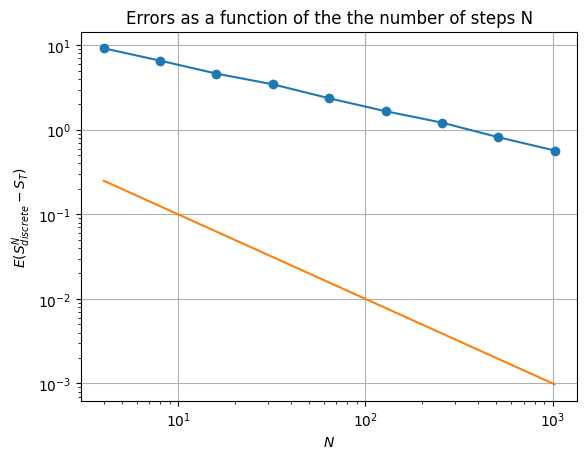

In [16]:
plt.title("Errors as a function of the the number of steps N")
plt.grid(True)
plt.plot(steps, errors,   marker="o")
plt.plot(steps, delta_ts)
plt.yscale("log", base=10)
plt.xscale("log", base=10)

plt.xlabel('$N$')
plt.ylabel('$E (S^N_{discrete}-S_T$)')

plt.show()

### Generating efficient paths

In Monte Carlo Simulation it will be useful to have a path generator that is efficient. This section discusses one improvement: antithetic variates. For every Random draw $\mathcal{N}$ used to build a path, we also use $-\mathcal {N}$ to build the mirror image path. In this way the average of the payoffs $V(-\mathcal N)$ and $V(\mathcal N)$ has lower variance than either
$$
\frac 1 2 ( V(-\mathcal N)+ V(\mathcal N)) ,
$$

thus dimishing the random-number generation


In [25]:
def generate_GBM_paths(S0=1,
                       rate=0.06, volatility=0.5, m_paths=2, t_exercise=1,
                       n_steps=252, seed=918723098,
                       antithetic=True):
    """ Function to generate random paths, requires numpy to run. Uses exact solution.
 """
    import numpy as np
    rng = np.random.default_rng(seed)
    dt = t_exercise / n_steps
    #use antithetic variates
    if antithetic:
        half = m_paths // 2
        Ns = rng.standard_normal((half, n_steps))
        Ns = np.concatenate([Ns, -Ns], axis=0)
    else:
        Ns = rng.standard_normal(size=(m_paths, n_steps))
    # Exact solution for GBM
    exp_factor = np.exp((rate - 0.5 * volatility ** 2) * dt + volatility * Ns * np.sqrt(dt))
    S_iterated = S0 * np.cumprod(exp_factor, axis=1)
    S = np.concatenate([np.full((m_paths, 1), S0), S_iterated], axis=1)
    return S

In [26]:
?generate_GBM_paths

Signature:
generate_GBM_paths(
    S0=1,
    rate=0.06,
    volatility=0.5,
    m_paths=2,
    t_exercise=1,
    n_steps=252,
    seed=918723098,
    antithetic=True,
)
Docstring:
Function to generate random paths, requires numpy to run. Uses exact solution 
!$S_T=S_0 \exp((\mu-rac {1}{2} \sigma^2)T + \sigma W_T)
File:      /tmp/ipykernel_11252/1136963123.py
Type:      function

In [23]:
#Let us consider a set of paths
set_of_m_paths= np.array([10, 50, 100, 1_000, 5_000, 10_000, 50_000, 100_000])

In [49]:
# And define a function where we can change the use of antithetic variates
def mc_call(S0=1,strike_price=1.1, rate=0.06, volatility=0.5, t_exercise=1, n_steps=252, m_paths=8, seed=918723098, antithetic=False):
   
    ST=generate_GBM_paths(S0=S0, rate=rate, volatility=volatility, m_paths= m_paths, t_exercise=t_exercise, n_steps=n_steps, 
                          seed=seed, antithetic=antithetic)
    payoff = np.maximum( ST -strike_price, 0.0)
    price = np.exp(-rate * t_exercise) * payoff.mean()
    standard_error   = np.exp(-rate * t_exercise) * payoff.std(ddof=1) / np.sqrt(m_paths)
    return price, standard_error   


In [50]:
errors_without_antithetic= np.array([mc_call(m_paths=val_path, antithetic=False)[1] for val_path in set_of_m_paths])
errors_with_antithetic= np.array([mc_call(m_paths=val_path, antithetic=True)[1] for val_path in set_of_m_paths])

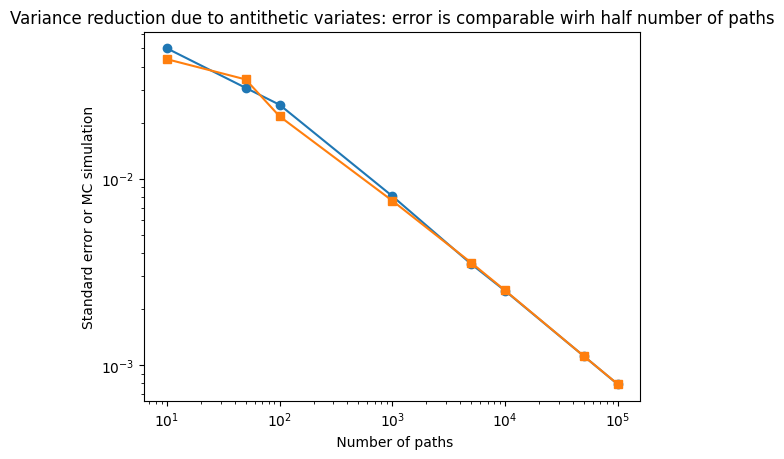

In [55]:
plt.plot(set_of_m_paths, errors_without_antithetic,   marker="o")
plt.plot(set_of_m_paths, errors_with_antithetic,   marker="s")

plt.yscale("log", base=10)
plt.xscale("log", base=10)
plt.xlabel(" Number of paths" )
plt.ylabel("Standard error or MC simulation" )
plt.title("Variance reduction due to antithetic variates: error is comparable wirh half number of paths")
plt.show()
